<a href="https://colab.research.google.com/github/asmkushvaha616-ops/NLP-sentiment-analysis-/blob/main/nlp_sentiment_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import pandas as pd
tweets = [
    # 😊 positive
    "I love this phone",
    "Great camera quality",
    "Best update ever",
    "Amazing battery life",
    "Thank you for the fast support",
    # 😡 negative
    "I hate this phone",
    "Terrible camera quality",
    "Worst update ever",
    "Battery dies so fast",
    "The support was very slow",
    # 😐 neutral
    "The event starts at 5pm",
    "New update is out today",
    "The phone comes in three colors",
    "Store opens at 10am",
    "The price varies by country",
]

labels = ["positive"] * 5 + ["negative"] * 5 + ["neutral"] * 5

df = pd.DataFrame({"text": tweets, "label": labels})
df

,text,label
0,I love this phone,positive
1,Great camera quality,positive
2,Best update ever,positive
3,Amazing battery life,positive
4,Thank you for the fast support,positive
5,I hate this phone,negative
6,Terrible camera quality,negative
7,Worst update ever,negative
8,Battery dies so fast,negative
9,The support was very slow,negative


In [2]:
# EDA
df.head()

,text,label
0,I love this phone,positive
1,Great camera quality,positive
2,Best update ever,positive
3,Amazing battery life,positive
4,Thank you for the fast support,positive


In [3]:
df.shape

(15, 2)

In [4]:
df["label"].value_counts()

,count
label,
positive,5
negative,5
neutral,5


In [5]:
df["word_count"] = df["text"].apply(lambda x: len(x.split()))
df[["text","label","word_count"]]


,text,label,word_count
0,I love this phone,positive,4
1,Great camera quality,positive,3
2,Best update ever,positive,3
3,Amazing battery life,positive,3
4,Thank you for the fast support,positive,6
5,I hate this phone,negative,4
6,Terrible camera quality,negative,3
7,Worst update ever,negative,3
8,Battery dies so fast,negative,4
9,The support was very slow,negative,5


In [6]:
df.groupby("label")["word_count"].mean()

,word_count
label,
negative,3.8
neutral,5.0
positive,3.8


In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

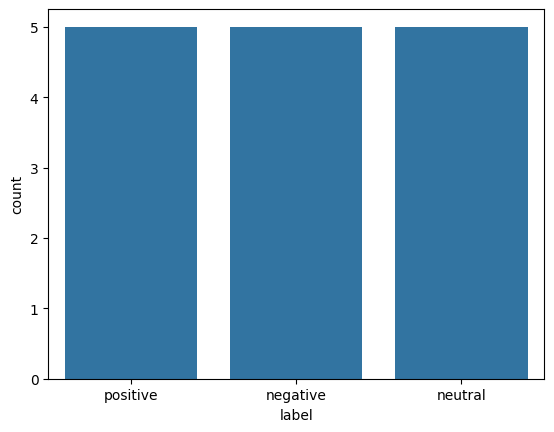

In [13]:
sns.countplot(data=df, x="label")
plt.show()

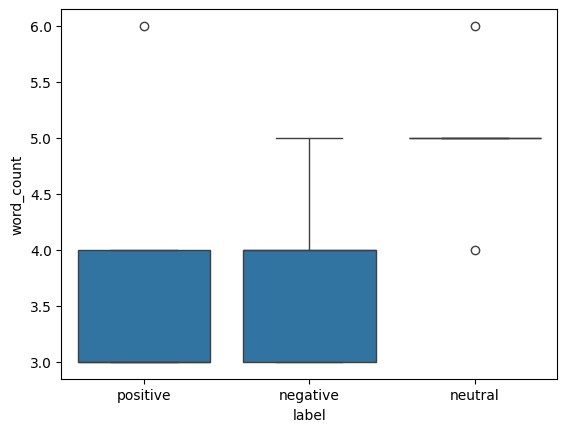

In [16]:
sns.boxplot(data=df, x="label", y="word_count")

plt.show()

In [14]:
import nltk
import string

In [19]:
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

In [18]:
nltk.download("stopwords")
nltk.download("wordnet")

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!


True

In [20]:
stop_words = set(stopwords.words("english"))
Lemmatizer = WordNetLemmatizer()

In [ ]:
stopwords()

In [30]:
# creating a processing function

def preprocess(text):
  text = text.lower()  #lower case

  text = text.translate(str.maketrans("", "", string.punctuation)) #removing punctuation

  words = text.split()
  words = [Lemmatizer.lemmatize(word) for word in words if word not in stop_words]

  return " ".join(words)

In [31]:
example = "i hate this phone."
preprocess(example)

'hate phone'

In [32]:
df["clean_text"] = df["text"].apply(preprocess)
df[["text","clean_text", "label"]]

,text,clean_text,label
0,I love this phone,love phone,positive
1,Great camera quality,great camera quality,positive
2,Best update ever,best update ever,positive
3,Amazing battery life,amazing battery life,positive
4,Thank you for the fast support,thank fast support,positive
5,I hate this phone,hate phone,negative
6,Terrible camera quality,terrible camera quality,negative
7,Worst update ever,worst update ever,negative
8,Battery dies so fast,battery dy fast,negative
9,The support was very slow,support slow,negative


In [33]:
# turn word into numbers
# vectorization ---> many method , one of this is
from sklearn.feature_extraction.text import CountVectorizer

In [36]:
from numpy import vectorize


In [35]:
sentences = ["love camera", "hate camera"]

vectorizer = CountVectorizer()

bow = vectorizer.fit_transform(sentences)

pd.DataFrame(bow.toarray(), columns = vectorizer.get_feature_names_out())

,camera,hate,love
0,1,0,1
1,1,1,0


In [41]:
from sklearn.feature_extraction.text import CountVectorizer

vectorizer = CountVectorizer()

features = vectorizer.fit_transform(df["clean_text"])

labels = df["label"]

# pd.DataFrame(features.toarray(), columns = vectorize)

In [42]:
features.shape

(15, 33)

In [44]:
pd.DataFrame(features.toarray(), columns = vectorizer.get_feature_names_out())

,10am,5pm,amazing,battery,best,camera,color,come,country,dy,...,start,store,support,terrible,thank,three,today,update,varies,worst
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,1,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,1,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,0
3,0,0,1,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,1,0,0,0,0,0
5,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
6,0,0,0,0,0,1,0,0,0,0,...,0,0,0,1,0,0,0,0,0,0
7,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,1,0,1
8,0,0,0,1,0,0,0,0,0,1,...,0,0,0,0,0,0,0,0,0,0
9,0,0,0,0,0,0,0,0,0,0,...,0,0,1,0,0,0,0,0,0,0


In [45]:
from sklearn.naive_bayes import MultinomialNB

In [46]:
model = MultinomialNB()
model.fit(features, labels)

MultinomialNB()

In [47]:
def predict(text):
  cleaned_text = preprocess(text)
  vector = vectorizer.transform([cleaned_text])
  prediction = model.predict(vector)
  return prediction[0]

In [49]:
print(predict("i love this phone!!"))

positive


In [50]:
print(predict("i hate this phone"))

negative


In [51]:
print(predict("the shop opens at 5PM"))

neutral


In [54]:
import joblib
joblib.dump(model, "model.pkl")
joblib.dump(vectorizer, "vectorizer.pkl")

['vectorizer.pkl']